# 7. A custom planet, end to end

The showcase tables cover 14 planets. `lazuli_exo.simulate` covers any
transiting planet from a dozen numbers. This notebook builds the parameter
dict by hand for **GJ 9827 d**, a warm sub-Neptune that is *not* in the
registry, runs it, and then shows the same thing through the form/report
layer a web page uses.

Values below are approximate literature numbers, rounded, for illustration
(radius 2.0 R⊕, mass 3.4 M⊕, T_eq ≈ 680 K, P = 6.2 d; K6V host, J = 7.98).
`simulate` needs `slicersim` and `sncosmo` installed (the noise is computed
live); `import lazuli_exo` itself stays numpy-only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo
from lazuli_exo import forms, report

R_EARTH_RJ, M_EARTH_MJ = 1 / 11.209, 1 / 317.83
params = dict(
    name="GJ 9827 d",
    # star
    teff_K=4294.0, logg=4.66, feh=-0.28, R_s_RSun=0.602, mag=7.984, band="J", mag_system="vega",
    # planet
    R_p_RJ=2.02 * R_EARTH_RJ, M_p_MJ=3.42 * M_EARTH_MJ, T_eq_K=680.0, t14_s=1.22 * 3600,
    # atmosphere (solar-metallicity, cloud-free H2/He to start)
    log_met=0.0, c_to_o=0.55, mu=None, log_P_cloud_bar=None, log_a_haze=None, haze_slope=-4.0,
)
obs = lazuli_exo.simulate(params, R=100, n_transits=10)
a, n = obs.meta["atmosphere"], obs.meta["noise"]
print(f"g = {a['g_ms2']:.1f} m/s2   H = {a['H_m']/1e3:.0f} km   mu = {a['mu_used']:.2f} ({a['mu_source']})")
print(f"feature amplitude {a['feature_amplitude_ppm']:.0f} ppm, median error {np.median(obs.depth_err)*1e6:.0f} ppm over 10 transits")
print(f"J = {n['mag_input']} Vega -> {n['mag_ab']:.2f} AB; readout {n['nmd_used']}, saturated px {n['nsaturated_detpx']}")
print(obs.detect())

g = 8.2 m/s2   H = 295 km   mu = 2.32 (chemistry)
feature amplitude 890 ppm, median error 18 ppm over 10 transits
J = 7.984 Vega -> 8.88 AB; readout [2, 2, 0], saturated px 0
{'template_snr_diagonal': 47.23190847192487, 'band_snr': {'Na': 10.842519905505153, 'K': 7.004023540811753, 'H2O': 30.68382366903079, 'CH4': 21.92682381399734, 'CO2': 15.790864657677979}}


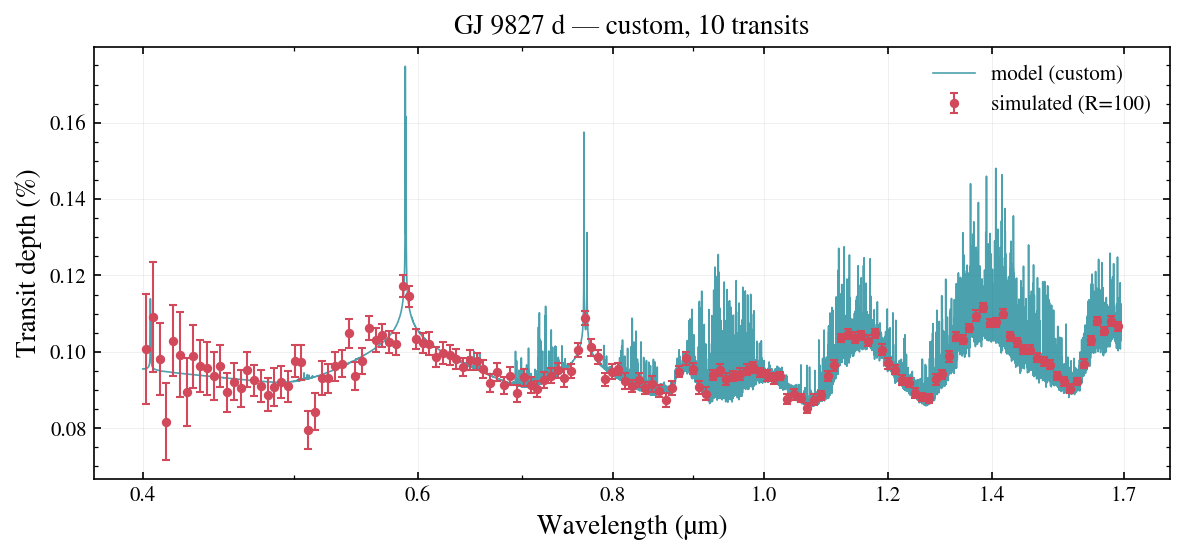

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.8))
obs.plot(ax=ax, seed=1)
fig.tight_layout()

## Heavier atmosphere, and a cloud deck

Two edits a user would make: a water-rich envelope (μ = 10) and a deck at
10 mbar. The scale height shrinks with μ, and the deck hides everything
below it; the derived numbers say how much.

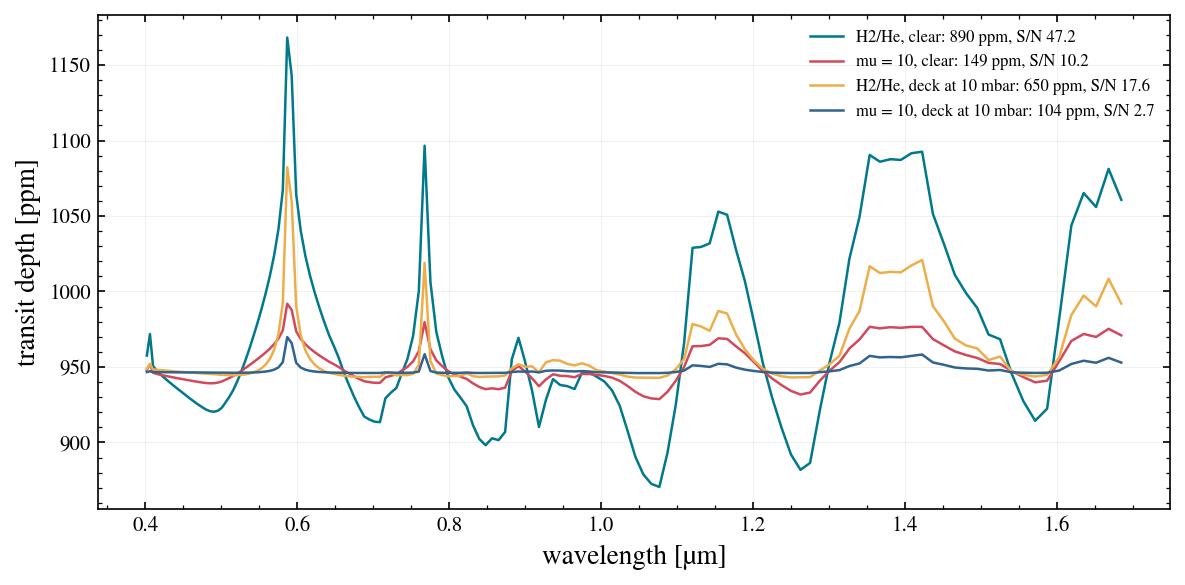

In [3]:
variants = {
    "H2/He, clear": {},
    "mu = 10, clear": dict(mu=10.0),
    "H2/He, deck at 10 mbar": dict(log_P_cloud_bar=-2.0),
    "mu = 10, deck at 10 mbar": dict(mu=10.0, log_P_cloud_bar=-2.0),
}
fig, ax = plt.subplots(figsize=(8, 4))
for label, edit in variants.items():
    o = lazuli_exo.simulate({**params, **edit}, R=100, n_transits=10)
    amp = o.meta["atmosphere"]["feature_amplitude_ppm"]
    snr = o.detect()["template_snr_diagonal"]
    ax.plot(o.wavelength, o.depth * 1e6, lw=1.2, label=f"{label}: {amp:.0f} ppm, S/N {snr:.1f}")
ax.set_xlabel("wavelength [µm]"); ax.set_ylabel("transit depth [ppm]"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

## The same run through the web layer

A web page never builds the params dict directly. It hands the raw form
strings to `lazuli_exo.forms.parse`, which applies defaults, clamps ranges
(with warnings) and rejects what cannot run (errors); `forms.to_params`
maps the typed values onto `simulate`; `lazuli_exo.report.summary` turns the
result into plain JSON for plotting. The local Flask applet and the Django
simulators page both use exactly this path.

In [4]:
form = {"planet_name": "GJ 9827 d", "teff": "4294", "logg": "4.66", "feh": "-0.28", "rstar": "0.602",
        "mag": "7.984", "band": "J", "mag_system": "vega", "rp": f"{2.02 * R_EARTH_RJ:.4f}",
        "mp": f"{3.42 * M_EARTH_MJ:.5f}", "teq": "680", "t14_h": "1.22",
        "log_met": "0.0", "c_to_o": "0.55", "mu": "", "log_p_cloud": "-2", "log_a_haze": "",
        "n_transits": "10", "resolution": "100", "seed": "1", "instrument_config": "cbe",
        "logg_typo": "ignored", "c_to_o": "1.7"}          # one out-of-range value on purpose
res = forms.parse(form)
print("errors:  ", res.errors)
print("warnings:", res.warnings)
o = lazuli_exo.simulate(forms.to_params(res.values), R=res.values["resolution"], n_transits=res.values["n_transits"])
s = report.summary(o, seed=res.values["seed"])
print(sorted(s))
print(s["result"])
for row in s["derived"]:
    print(f"  {row['label']:18s} {row['value']}" + (f"   [{row['cls']}]" if row["cls"] else ""))

errors:   []
warnings: ['c_to_o=1.7 outside [0.3, 1], clamped to 1']


['R', 'caveats', 'depth', 'depth_err', 'derived', 'feature_snr', 'flat_depth', 'model_depth', 'model_wavelength', 'n_transits', 'noise_validated', 'planet', 'points', 'result', 'scenario', 'seed', 'wavelength']
{'template_snr_diagonal': 20.993808317280365, 'feature_amplitude_ppm': 652.0270530167058, 'median_err_ppm': 18.174328501644617, 'n_bins': 145}
  g                  8.2 m/s²
  H                  294 km (H/Rp = 0.0228)
  mu                 2.32 (chemistry)
  T for chemistry    680 K
  feature amplitude  652 ppm (0.40–1.70 µm)
  column slope       0.81
  stellar SED        phoenix
  magnitude          7.98 J vega → 8.88 AB (offset +0.899)
  readout            2:2:0, t_obs = 11.3 s, lazuli_cbe
  saturated pixels   0
  slicersim          1.0.0


## Summary

- A dozen numbers describe the system; `simulate` returns the same
  `SimulatedSpectrum` the showcase tables do, so `detect()`, `plot()` and
  `simulate_points()` work unchanged.
- μ and the deck pressure are the two knobs that move a sub-Neptune's
  amplitude the most; the derived panel reports H, H/R_p and the μ source.
- `forms` + `report` are the whole web contract: strings in, JSON out.